In [2]:
#Ej 3
import os
import matplotlib.pyplot as plt
import sys
sys.path.append('../../')
import patch
import shutil
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.datasets import ImageFolder
from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR
from torch.nn.functional import softmax
import pandas as pd
import time

# Seleccionar dispositivo: GPU si está disponible, sino CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

# Habilitar Tensor Cores en GPU (NVIDIA RTX 3070) para mayor rendimiento.
# Si ejecutas en otro hardware sin soporte TF32, desactiva los allow_tf32:
# torch.backends.cuda.matmul.allow_tf32 = False
# torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

Usando dispositivo: cuda


In [3]:
# Transformación básica para las imágenes:
# Convierte a tensor y normaliza cada canal a rango [-1, 1]
basic_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

In [4]:

# Carga dataset de parches usando ImageFolder y aplica transformaciones
data_root = '../../data/patches'
full_ds = datasets.ImageFolder(data_root, transform=basic_tfm)
print("Clases:", full_ds.classes)
print("Total parches:", len(full_ds))

# Divide dataset en entrenamiento (80%) y validación (20%)
n = len(full_ds)
n_train = int(0.8 * n)
n_val   = n - n_train

train_ds, val_ds = random_split(
    full_ds, [n_train, n_val],
    generator=torch.Generator().manual_seed(73) # semilla fija para reproducibilidad
)
print("Train / Val:", n_train, "/", n_val)


Clases: ['Coleus neochilus', 'Salvia microphylla', 'Salvia uliginosa']
Total parches: 2712
Train / Val: 2169 / 543


In [5]:
# Configura DataLoaders con BATCH_SIZE adaptable:
# El tamaño de lote (BATCH_SIZE) debe ajustarse según la GPU disponible;
# en mi RTX 3070, BATCH_SIZE = 1024 funciona bien, pero podrías bajarlo en GPUs con menos VRAM.
BATCH_SIZE = 1024

def make_loader(ds, bs, shuffle):
    return DataLoader(
        ds, batch_size=bs, shuffle=shuffle,
        pin_memory=True, num_workers=os.cpu_count(),
        prefetch_factor=4, persistent_workers=True
    )
train_dl = make_loader(train_ds, BATCH_SIZE, True)
val_dl   = make_loader(val_ds,   BATCH_SIZE, False)


In [6]:
# Obtener patch_size automáticamente del dataset
sample_img, _ = full_ds[0]
patch_size = sample_img.shape[1]

class PlantCNN(nn.Module):

    # Defino modelo CNN para clasificación de parches\class PlantCNN(nn.Module):
    def __init__(self, patch_size, n_classes):
        super().__init__()
        # Bloques convolucionales con pooling para reducir dimensionalidad
        self.conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout(0.5) # Regularización
        )
        # Calcular tamaño de la salida plana tras los pooling (división por 2 tres veces)
        fs  = patch_size // 8
        flat = 64 * fs * fs
        # Capas completamente conectadas para clasificación
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 64), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, n_classes)
        )
    def forward(self, x):
        # Propagación hacia adelante: convoluciones + FC
        return self.fc(self.conv(x))

# Instancia y mueve modelo al dispositivo
model = PlantCNN(patch_size, len(full_ds.classes)).to(device)
print(model)


PlantCNN(
  (conv): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout(p=0.5, inplace=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=9216, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [7]:
epochs = 230
# optimizer y scheduler
optimizer = AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = OneCycleLR(
    optimizer,
    max_lr=1e-3,
    steps_per_epoch=len(train_dl),
    epochs= epochs,
    pct_start=0.1,
    anneal_strategy='cos'
)

criterion = nn.CrossEntropyLoss()
history = {"train_loss":[], "val_loss":[]}

for ep in range(1, epochs+1):
    # — Train —
    model.train()
    run_train = 0
    t0 = time.time()
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        
        preds = model(xb)
        loss = criterion(preds, yb)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        
        run_train += loss.item() * xb.size(0)
    train_loss = run_train / len(train_dl.dataset)
    
    # — Val —
    model.eval()
    run_val = 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            run_val += loss.item() * xb.size(0)
    val_loss = run_val / len(val_dl.dataset)
    val_correct = 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            preds   = model(xb).argmax(1)
            val_correct += (preds == yb).sum().item()
    val_acc = val_correct / len(val_dl.dataset)
    
    # guardar historiales
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    
    print(f"Ep {ep}/{epochs} | {time.time()-t0:.1f}s "
          f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"val_acc={val_acc:.3f}")


Ep 1/230 | 85.9s train_loss=1.0968 val_loss=1.0914 val_acc=0.378
Ep 2/230 | 1.6s train_loss=1.0947 val_loss=1.0888 val_acc=0.378
Ep 3/230 | 1.5s train_loss=1.0917 val_loss=1.0862 val_acc=0.446
Ep 4/230 | 1.6s train_loss=1.0917 val_loss=1.0829 val_acc=0.424
Ep 5/230 | 1.5s train_loss=1.0859 val_loss=1.0769 val_acc=0.425
Ep 6/230 | 1.5s train_loss=1.0778 val_loss=1.0687 val_acc=0.420
Ep 7/230 | 1.5s train_loss=1.0681 val_loss=1.0514 val_acc=0.451
Ep 8/230 | 1.6s train_loss=1.0494 val_loss=1.0237 val_acc=0.488
Ep 9/230 | 1.6s train_loss=1.0198 val_loss=0.9850 val_acc=0.530
Ep 10/230 | 1.6s train_loss=0.9753 val_loss=0.9331 val_acc=0.540
Ep 11/230 | 1.6s train_loss=0.9302 val_loss=0.8856 val_acc=0.558
Ep 12/230 | 1.6s train_loss=0.8927 val_loss=0.8560 val_acc=0.552
Ep 13/230 | 1.5s train_loss=0.8608 val_loss=0.8766 val_acc=0.554
Ep 14/230 | 1.6s train_loss=0.8627 val_loss=0.8682 val_acc=0.545
Ep 15/230 | 1.5s train_loss=0.8712 val_loss=0.8668 val_acc=0.547
Ep 16/230 | 1.4s train_loss=0.851

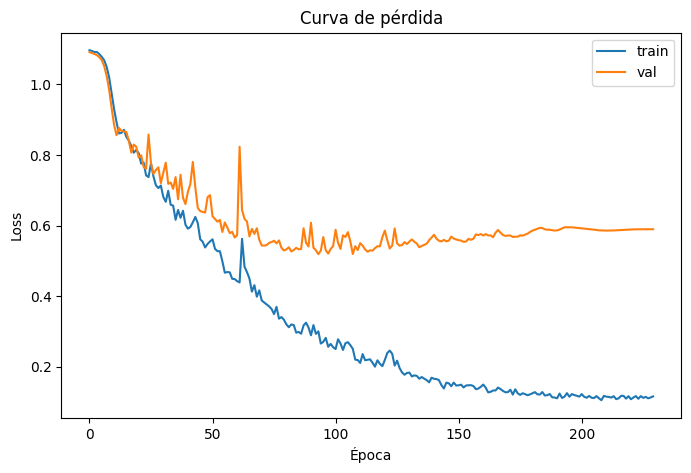

In [8]:
plt.figure(figsize=(8,5))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"],   label="val")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.title("Curva de pérdida")
plt.show()

In [9]:
# Calcular precisión del modelo sobre un DataLoader
def compute_acc(dl):
    """
    Evalúa el modelo en el loader y devuelve la precisión (correctos / total).
    """
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for xb, yb in dl:
            # Mover datos al dispositivo
            xb, yb = xb.to(device), yb.to(device)
            # Predicción y conteo de aciertos
            preds = model(xb).argmax(dim=1)
            correct += (preds == yb).sum().item()
            total   += yb.size(0)
    return correct / total

# Imprimir precisión en entrenamiento y validación
print(f"Train acc: {compute_acc(train_dl)*100:.1f}%")
print(f" Val  acc: {compute_acc(val_dl)*100:.1f}%")


Train acc: 98.7%
 Val  acc: 80.5%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.45098042].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9843137..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.90588236].
Clipping input data to the valid range for imshow

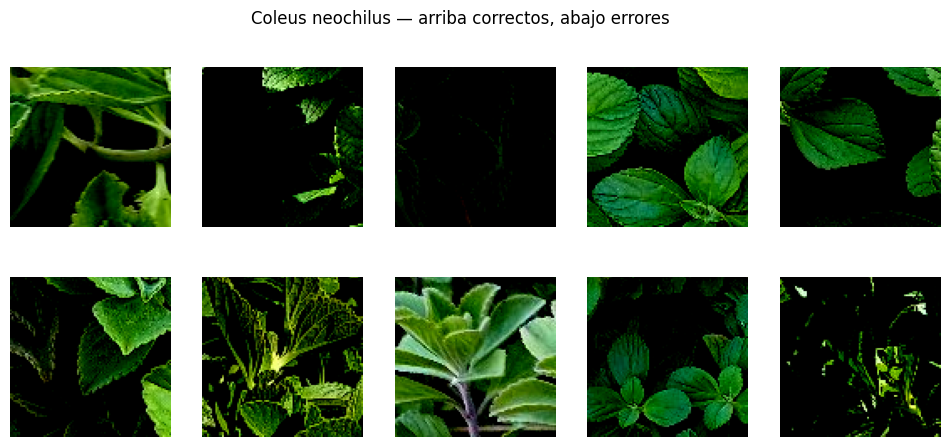

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.5686275].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.92941177..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.96862745..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.7254902].
Clipping input data to the valid range for 

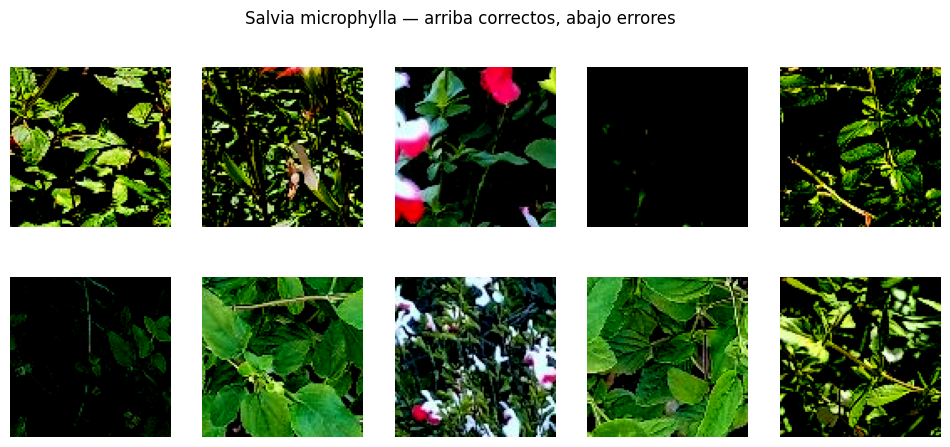

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.94509804].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.2313726].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with R

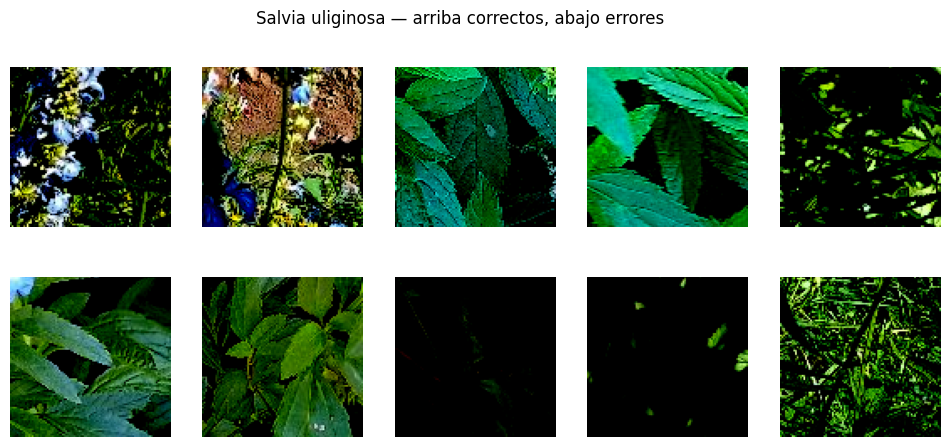

In [10]:
# Recopila imágenes, etiquetas y predicciones del conjunto de validación
imgs, labs, preds = [], [], []
with torch.no_grad():
    for xb, yb in val_dl:
        # Mover lotes a dispositivo
        xb, yb = xb.to(device), yb.to(device)
        # Obtener predicciones de la clase más probable
        pr = model(xb).argmax(1)
        # Almacenar tensores en CPU para visualización
        imgs.append(xb.cpu()); labs.append(yb.cpu()); preds.append(pr.cpu())

# Concatenar todos los tensores en uno solo
imgs = torch.cat(imgs)
labs = torch.cat(labs)
preds = torch.cat(preds)

# Mostrar 5 ejemplos correctos y 5 erróneos para cada clase
for cls in range(len(full_ds.classes)):
    # Índices de muestras de la clase cls
    idxs = (labs == cls).nonzero().flatten()
    # Seleccionar primeros 5 correctos y 5 erróneos
    correct = [i for i in idxs if preds[i]==cls][:5]
    wrong   = [i for i in idxs if preds[i]!=cls][:5]
    # Crear figura con dos filas: correctos arriba, errores abajo
    fig, axes = plt.subplots(2,5,figsize=(12,5))
    fig.suptitle(f"{full_ds.classes[cls]} — arriba correctos, abajo errores")
    for i in range(5):
        # Mostrar imagen correcta
        axes[0,i].imshow(imgs[correct[i]].permute(1,2,0))
        axes[0,i].axis("off")
        # Mostrar imagen errónea
        axes[1,i].imshow(imgs[wrong[i]].permute(1,2,0))
        axes[1,i].axis("off")
    plt.show()


In [13]:
# Directorios
input_dir = r"mis_fotos"
output_dir = r"patches"

# Para cada archivo de imagen en input_dir, crea una subcarpeta con el nombre base y mueve la imagen allí.
for fname in os.listdir(input_dir):
    if fname.lower().endswith((".jpg", ".png")):
        full_path = os.path.join(input_dir, fname)
        if os.path.isfile(full_path):
            base = os.path.splitext(fname)[0]
            new_dir = os.path.join(input_dir, base)
            if not os.path.exists(new_dir):
                os.makedirs(new_dir)
            new_path = os.path.join(new_dir, fname)
            if not os.path.exists(new_path):
                shutil.move(full_path, new_path)

# Crea lista de categorías
categories = [d for d in os.listdir(input_dir) if os.path.isdir(os.path.join(input_dir, d))]

# Parámetros para extraer parches
patchSize = 96
scale = 1
offset = 0
stride = 20

# Llamada a la función de patch.py para generar los parches.
patch.createPatchesData(input_dir, output_dir, categories, patchSize, scale, offset, stride, verbose=True)

# Carga el dataset de parches generado
patches_ds = ImageFolder(output_dir, transform=basic_tfm)
patches_loader = DataLoader(patches_ds, batch_size=64, shuffle=False, num_workers=2)

# Realiza predicciones con el modelo entrenado
model.eval()
all_preds = []
with torch.no_grad():
    for imgs, _ in patches_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())

# Agrupa predicciones por foto original
results = {}
for idx, (img_path, _) in enumerate(patches_ds.samples):
    base = os.path.basename(img_path)
    photo_name = base.split('_')[0]
    if photo_name not in results:
        results[photo_name] = []
    results[photo_name].append(all_preds[idx])

# Realiza votación mayoritaria para cada foto
print("\nResultados de clasificación por foto:")
for photo, preds in results.items():
    votes = {}
    for p in preds:
        class_name = full_ds.classes[p]
        votes[class_name] = votes.get(class_name, 0) + 1
    winner_class = max(votes.items(), key=lambda x: x[1])[0]
    total_votes = len(preds)
    winner_votes = votes[winner_class]
    print(f"Foto '{photo}.jpg' clasificada como {winner_class} ({winner_votes}/{total_votes} parches, {winner_votes/total_votes*100:.1f}%)")

100%|██████████| 1/1 [00:00<00:00, 14.04it/s]


140 patches were created for the foto1 category.


100%|██████████| 1/1 [00:00<00:00, 12.07it/s]


165 patches were created for the foto2 category.


100%|██████████| 1/1 [00:00<00:00, 11.40it/s]


165 patches were created for the foto3 category.

Resultados de clasificación por foto:
Foto 'foto1.jpg' clasificada como Coleus neochilus (125/140 parches, 89.3%)
Foto 'foto2.jpg' clasificada como Coleus neochilus (105/165 parches, 63.6%)
Foto 'foto3.jpg' clasificada como Salvia uliginosa (104/165 parches, 63.0%)


Se logró clasificar correctamente la foto 1 y la foto 3, lo que indica que el enfoque de extracción de parches y votación mayoritaria puede funcionar bien en condiciones adecuadas.
En la foto 2 se observó una confusión en la clasificación, probablemente debido a la presencia simultánea de dos plantas en la imagen, lo que dispersa la evidencia en los parches.
Este resultado sugiere la necesidad de aplicar técnicas de segmentación o de análisis espacial previo para focalizar correctamente la planta de interés antes de extraer los parches.
En resumen, la calidad en la selección y agrupación de parches es crucial para obtener una clasificación robusta y precisa.

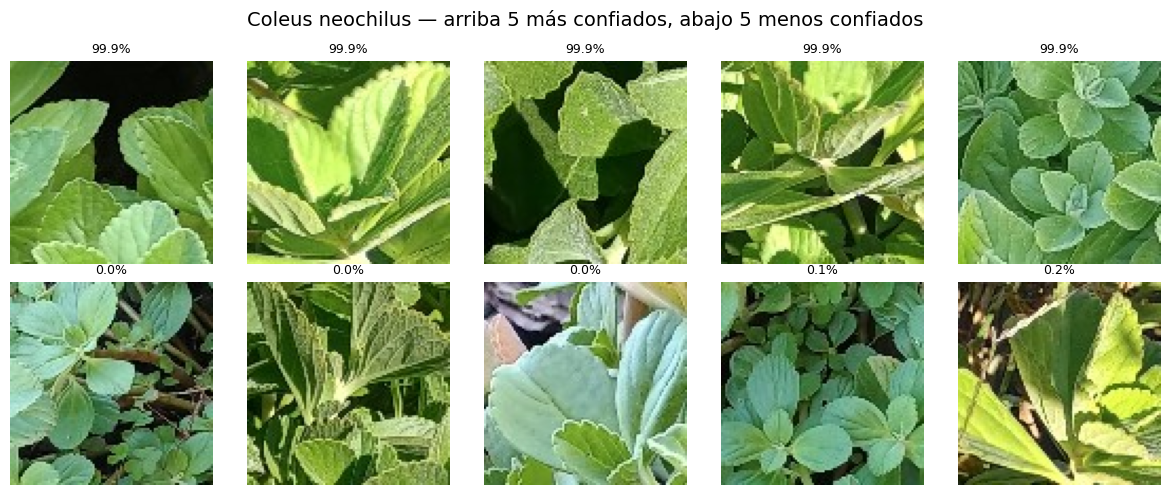

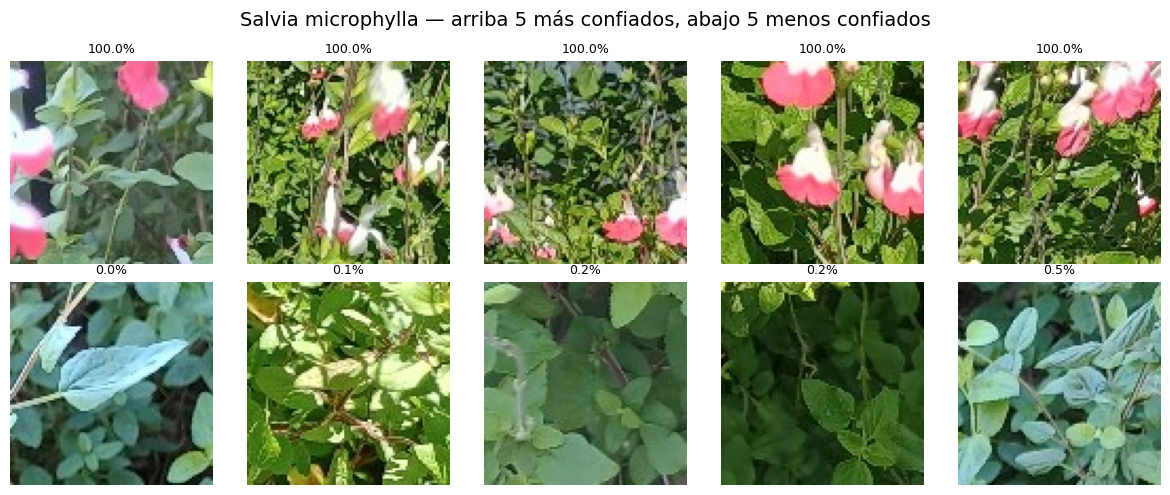

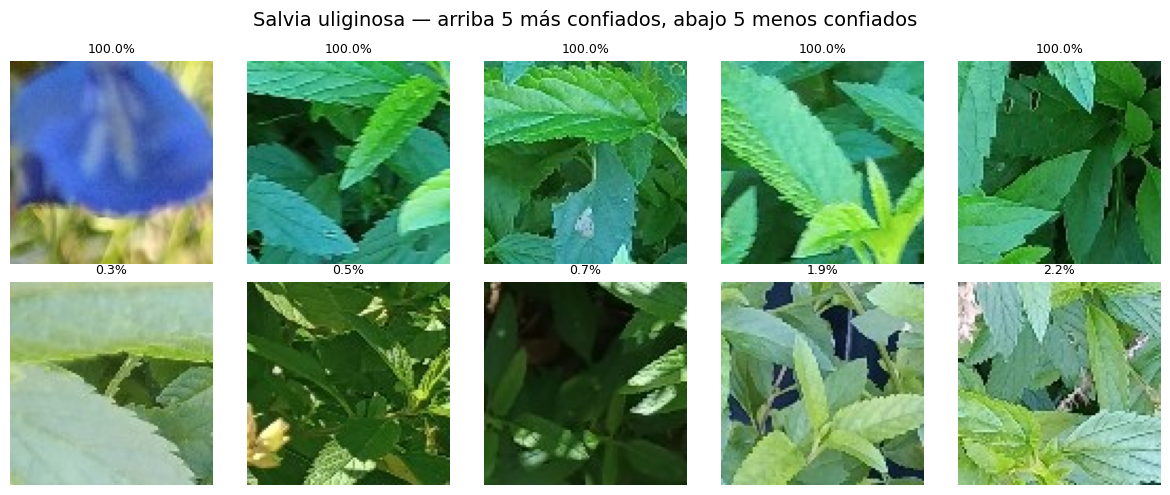

In [12]:

def denorm(t):                       # des-normaliza
    return (t * 0.5 + 0.5).clamp(0, 1)

# probabilidad de la clase verdadera para cada parche 
rows = []
model.eval()
with torch.no_grad():
    for xb, yb in val_dl:
        xb, yb = xb.to(device), yb.to(device)
        probs = softmax(model(xb), dim=1).cpu()

        for i in range(xb.size(0)):
            rows.append({
                "tensor": xb[i].cpu(),
                "true":   yb[i].item(),
                "prob_true": probs[i, yb[i]].item()
            })

df = pd.DataFrame(rows)
classes = full_ds.classes        

# Grafica 5 mejores vs 5 peores para cada especie
for cls_id, cls_name in enumerate(classes):
    sub    = df[df.true == cls_id]
    best5  = sub.nlargest(5, "prob_true")
    worst5 = sub.nsmallest(5, "prob_true")

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    fig.suptitle(f"{cls_name} — arriba 5 más confiados, abajo 5 menos confiados", fontsize=14)

    # fila superior → mejores
    for i, (_, row) in enumerate(best5.iterrows()):
        axes[0, i].imshow(denorm(row.tensor).permute(1, 2, 0))
        axes[0, i].set_title(f"{row.prob_true*100:.1f}%", fontsize=9)
        axes[0, i].axis("off")

    # fila inferior → peores
    for i, (_, row) in enumerate(worst5.iterrows()):
        axes[1, i].imshow(denorm(row.tensor).permute(1, 2, 0))
        axes[1, i].set_title(f"{row.prob_true*100:.1f}%", fontsize=9)
        axes[1, i].axis("off")

    plt.tight_layout()
    plt.show()

En los parches “flojos” el CNN pierde sus pistas principales: en Coleus neochilus la iluminación dura o la sobreexposición ocultan las vetas dentadas; en Salvia microphylla predominan hojas sin las corolas rojo-blanco que el modelo aprendió como rasgo distintivo; y en Salvia uliginosa el desenfoque o los verdes lavados diluyen el tono azul-violáceo de sus flores. Estas condiciones (sombras extremas, blur, recortes que excluyen la flor) alteran texturas y colores, y revelan un sesgo del set de entrenamiento hacia imágenes bien enfocadas y con la flor visible. Como el modelo se apoya sobre todo en “color + forma nítida”, cuando esa señal se degrada su confianza cae drásticamente, provocando las clasificaciones pobres observadas.